# 04 · Alternating Least Squares (matrix factorisation)

Approximate the rating matrix with low-rank factors $R \approx P Q^\top$, $p_u, q_i \in \mathbb R^f$. With one factor matrix fixed the loss is a ridge regression in the other, so ALS alternates two closed-form solves.

Two variants, because rating prediction and ranking need different objectives:

| | **implicit ALS** (`implicit` library) | **explicit ALS** (NumPy, `src/models.py`) |
|---|---|---|
| data | all cells; observed = positive with confidence $c_{ui}=1+\alpha r_{ui}$, unobserved = 0 with confidence 1 | observed ratings only |
| loss | $\sum_{u,i} c_{ui}(p_{ui}-x_u^\top y_i)^2 + \lambda(\lVert X\rVert^2+\lVert Y\rVert^2)$ | $\sum_{(u,i)\in\Omega}(r_{ui}-\mu-b_u-b_i-p_u^\top q_i)^2 + \lambda\sum_u n_u\lVert p_u\rVert^2 + \lambda\sum_i n_i\lVert q_i\rVert^2$ |
| output | preference score (not a rating) | star rating |
| used for | ranking metrics | RMSE |

`implicit` implements Hu, Koren & Volinsky (2008) and is well suited to top-K ranking, but it cannot predict ratings, so a small explicit ALS (with user/item biases, ALS-WR regularisation) is implemented for RMSE.

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 4); pd.set_option("display.width", 140)
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

def save_params(name, params):
    path = RESULTS / "best_params.json"
    allp = json.loads(path.read_text()) if path.exists() else {}
    allp[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}
    path.write_text(json.dumps(allp, indent=2))

In [2]:
from src.data import load_ratings, load_movies, temporal_user_split
ratings, movies = load_ratings(), load_movies()
train, test = temporal_user_split(ratings, test_frac=0.2)        # final evaluation
train_in, valid = temporal_user_split(train, test_frac=0.2)      # hyper-parameter tuning only
title = movies.set_index("item_idx")["title"]
print(f"train={len(train)} test={len(test)} | train_in={len(train_in)} valid={len(valid)}")

train=80000 test=20000 | train_in=64005 valid=15995


In [3]:
from src.models import ImplicitALSRecommender, ExplicitALSRecommender
from src.evaluation import grid_search, evaluate_ranking, evaluate_rmse, recommend_top_k

## Implicit ALS — hyper-parameter search (validation NDCG@10)

In [4]:
grid_ials = grid_search(ImplicitALSRecommender,
                        {"factors": [8, 16, 32, 64, 128], "regularization": [0.1, 1.0, 5.0, 20.0],
                         "alpha": [0.1, 0.25, 0.5, 2.0], "iterations": [15]},
                        train_in, valid, objective="ndcg@10", verbose=False)
grid_ials.head(10)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,factors,regularization,alpha,iterations,precision@10,recall@10,ndcg@10,coverage@10
0,64,5.0,0.10,15,0.1101,0.1736,0.1643,0.1807
1,128,5.0,0.10,15,0.1077,0.1706,0.1623,0.1831
2,32,5.0,0.10,15,0.1095,0.1730,0.1614,0.1653
3,64,20.0,0.50,15,0.1096,0.1705,0.1599,0.1795
4,128,20.0,0.50,15,0.1087,0.1698,0.1589,0.1819
5,32,20.0,0.50,15,0.1082,0.1681,0.1587,0.1784
6,32,5.0,0.25,15,0.1057,0.1694,0.1576,0.2176
7,16,5.0,0.10,15,0.1033,0.1630,0.1533,0.1474
8,64,5.0,0.25,15,0.0985,0.1637,0.1527,0.2562
9,16,5.0,0.25,15,0.1043,0.1645,0.1521,0.1843


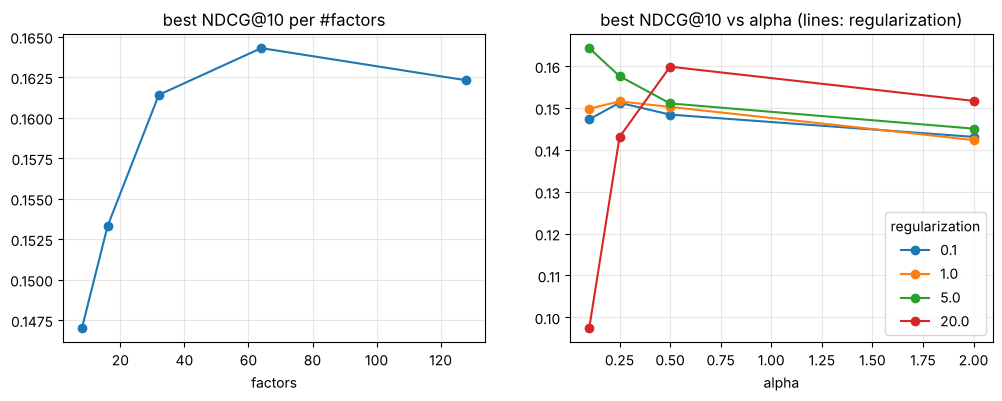

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
grid_ials.groupby("factors")["ndcg@10"].max().plot(marker="o", ax=ax[0], title="best NDCG@10 per #factors")
grid_ials.pivot_table(index="alpha", columns="regularization", values="ndcg@10", aggfunc="max").plot(
    marker="o", ax=ax[1], title="best NDCG@10 vs alpha (lines: regularization)")
for a in ax: a.grid(alpha=.3)

## Explicit ALS — hyper-parameter search (validation RMSE)

In a preliminary run 100 and 200 factors improved validation RMSE by less than 0.001 over 50 factors while being much slower (pure-NumPy solver), so the grid stops at 50.

In [6]:
grid_eals = grid_search(ExplicitALSRecommender,
                        {"factors": [10, 20, 50], "regularization": [0.05, 0.1, 0.15, 0.2, 0.3], "iterations": [15]},
                        train_in, valid, objective="rmse", verbose=False)
grid_eals.head(10)

,factors,regularization,iterations,rmse
0,50,0.15,15,0.9617
1,20,0.15,15,0.9628
2,10,0.15,15,0.9649
3,20,0.20,15,0.9662
4,50,0.20,15,0.9662
5,50,0.10,15,0.9664
6,10,0.20,15,0.9668
7,20,0.10,15,0.9762
8,10,0.10,15,0.9767
9,10,0.30,15,0.9767


In [7]:
best_ials = grid_ials.iloc[0][["factors", "regularization", "alpha", "iterations"]].to_dict()
best_eals = grid_eals.iloc[0][["factors", "regularization", "iterations"]].to_dict()
for d in (best_ials, best_eals):
    d["factors"], d["iterations"] = int(d["factors"]), int(d["iterations"])
save_params("ials", best_ials); save_params("eals", best_eals)
grid_ials.to_csv(RESULTS / "grid_ials.csv", index=False); grid_eals.to_csv(RESULTS / "grid_eals.csv", index=False)
best_ials, best_eals

({'factors': 64, 'regularization': 5.0, 'alpha': 0.1, 'iterations': 15},
 {'factors': 50, 'regularization': 0.15, 'iterations': 15})

## Movies close in the learned factor space

In [8]:
ials = ImplicitALSRecommender(**best_ials).fit(train)
Y = ials.item_factors_ / (np.linalg.norm(ials.item_factors_, axis=1, keepdims=True) + 1e-9)
for item_id in [50, 1, 98]:
    sims = Y @ Y[item_id - 1]; sims[item_id - 1] = -1
    print("==", title[item_id - 1], "->", "; ".join(title[np.argsort(-sims)[:6]]))

== Star Wars (1977) -> Return of the Jedi (1983); Toy Story (1995); Empire Strikes Back, The (1980); Raiders of the Lost Ark (1981); Godfather, The (1972); Men in Black (1997)
== Toy Story (1995) -> Star Wars (1977); Return of the Jedi (1983); Hercules (1997); Mr. Holland's Opus (1995); Independence Day (ID4) (1996); Rock, The (1996)
== Silence of the Lambs, The (1991) -> Jaws (1975); Pulp Fiction (1994); Forrest Gump (1994); Raiders of the Lost Ark (1981); Empire Strikes Back, The (1980); Alien (1979)


## Recommendations for one user

In [9]:
u = 0
rec = recommend_top_k(ials, train, [u], 10)[0]
liked = set(test[(test.user_idx == u) & (test.rating >= 4)].item_idx)
pd.DataFrame({"recommendation": title[rec].values, "in test & liked": [i in liked for i in rec]}, index=range(1, 11))

,recommendation,in test & liked
1,Fargo (1996),True
2,E.T. the Extra-Terrestrial (1982),False
3,Star Trek: The Wrath of Khan (1982),True
4,This Is Spinal Tap (1984),True
5,Young Frankenstein (1974),True
6,Monty Python's Life of Brian (1979),True
7,True Lies (1994),False
8,Mission: Impossible (1996),False
9,Mrs. Doubtfire (1993),False
10,Die Hard 2 (1990),False


## Test-set performance

In [10]:
eals = ExplicitALSRecommender(**best_eals).fit(train)
out = pd.DataFrame({
    "implicit ALS": evaluate_ranking(ials, train, test, ks=(10,)),
    "explicit ALS": {**evaluate_ranking(eals, train, test, ks=(10,)), "rmse": evaluate_rmse(eals, test)},
}).T
out

,precision@10,recall@10,ndcg@10,coverage@10,n_users,rmse
implicit ALS,0.1295,0.1532,0.1744,0.2224,906.0,NaN
explicit ALS,0.0498,0.0448,0.0576,0.1468,906.0,0.9773
